# g: Random and hybrid schedules vs methods A and B

Compares four ways to pre-schedule work. All schedule-based designs use B's run-time rule:
each live worker takes the first partition on its list that is not done.

- **A**: full monitoring (benchmark).
- **B**: pair schedules (own block with two pointers, then middle-out visiting orders).
- **Random**: each worker has its own random order of all N partitions.
- **Hybrid**: pair schedule on the own block, then its own random order through all other partitions.

Random and hybrid lists depend on the seed, so each value is the mean over `SEEDS` draws.
Each draw is fixed before the run (a pre-schedule), and then the exact recursions are used.

In [1]:
import statistics
import matplotlib.pyplot as plt
from pathlib import Path
from shared import *

Path("images").mkdir(exist_ok=True)

In [2]:
# ---------- Measures for one design ----------

def mean_rounds(distribution):
    return sum(t * p for t, p in distribution.items())


def A_measures(N, k, P):
    """(expected rounds, timed worst case, 95th percentile) for method A."""
    distribution = A_time_distribution(N, k, P)
    return mean_rounds(distribution), A_timed_worst(N, k, P), percentile_rounds(distribution, 0.95)


def schedule_measures(schedules, N, P):
    """(expected rounds, timed worst case, 95th percentile) for one set of task lists."""
    distribution = B_time_distribution(schedules, N, P)
    return mean_rounds(distribution), B_timed_worst(schedules, N, P), percentile_rounds(distribution, 0.95)


def random_design_measures(make_schedules, N, k, P, seeds):
    """Mean of each measure over several random draws of the task lists."""
    runs = [schedule_measures(make_schedules(N, k, seed), N, P) for seed in seeds]
    return tuple(statistics.mean(run[i] for run in runs) for i in range(3))

In [3]:
# ---------- Compute all results once ----------
# k = 10 (N = 20) takes several minutes per design, so it is left out here.

trial_cases = [(8, 4, 0.1), (12, 6, 0.1), (12, 6, 0.2), (16, 8, 0.1), (16, 8, 0.2)]
SEEDS = range(10)

results = {}
for N, k, P in trial_cases:
    results[(N, k, P)] = {
        "A": A_measures(N, k, P),
        "B": schedule_measures(pair_schedules(N, k), N, P),
        "random": random_design_measures(random_schedules, N, k, P, SEEDS),
        "hybrid": random_design_measures(hybrid_schedules, N, k, P, SEEDS),
    }

NameError: name 'random' is not defined

In [ ]:
# ---------- Tables ----------
designs = ["A", "B", "random", "hybrid"]
measure_names = ["Expected rounds", "Timed worst case (rounds)", "95th percentile (rounds)"]

for m, name in enumerate(measure_names):
    print(name)
    print(f"| {'N partitions':>12} | {'k workers':>9} | {'P':>4} | " + " | ".join(f"{d:>8}" for d in designs)
          + " | " + " | ".join(f"{d + ' gap':>10}" for d in designs[1:]) + " |")
    print("|" + "---|" * (3 + 2 * len(designs) - 1))
    for (N, k, P), r in results.items():
        values = [r[d][m] for d in designs]
        gaps = [100 * (v / values[0] - 1) for v in values[1:]]          # % above method A
        print(f"| {N:>12} | {k:>9} | {P:>4} | " + " | ".join(f"{v:>8.3f}" for v in values)
              + " | " + " | ".join(f"{g:>9.1f}%" for g in gaps) + " |")
    print()

Expected rounds
| N partitions | k workers |    P |        A |        B |   random |   hybrid |      B gap | random gap | hybrid gap |
|---|---|---|---|---|---|---|---|---|---|
|            8 |         4 |  0.1 |    2.828 |    2.828 |    3.675 |    2.883 |       0.0% |      29.9% |       1.9% |
|           12 |         6 |  0.1 |    2.908 |    3.041 |    3.981 |    3.054 |       4.6% |      36.9% |       5.0% |
|           12 |         6 |  0.2 |    4.084 |    4.307 |    5.135 |    4.304 |       5.5% |      25.7% |       5.4% |
|           16 |         8 |  0.1 |    2.970 |    3.206 |    4.121 |    3.155 |       7.9% |      38.7% |       6.2% |
|           16 |         8 |  0.2 |    4.165 |    4.629 |    5.518 |    4.511 |      11.1% |      32.5% |       8.3% |

Timed worst case (rounds)
| N partitions | k workers |    P |        A |        B |   random |   hybrid |      B gap | random gap | hybrid gap |
|---|---|---|---|---|---|---|---|---|---|
|            8 |         4 |  0.1 |    2

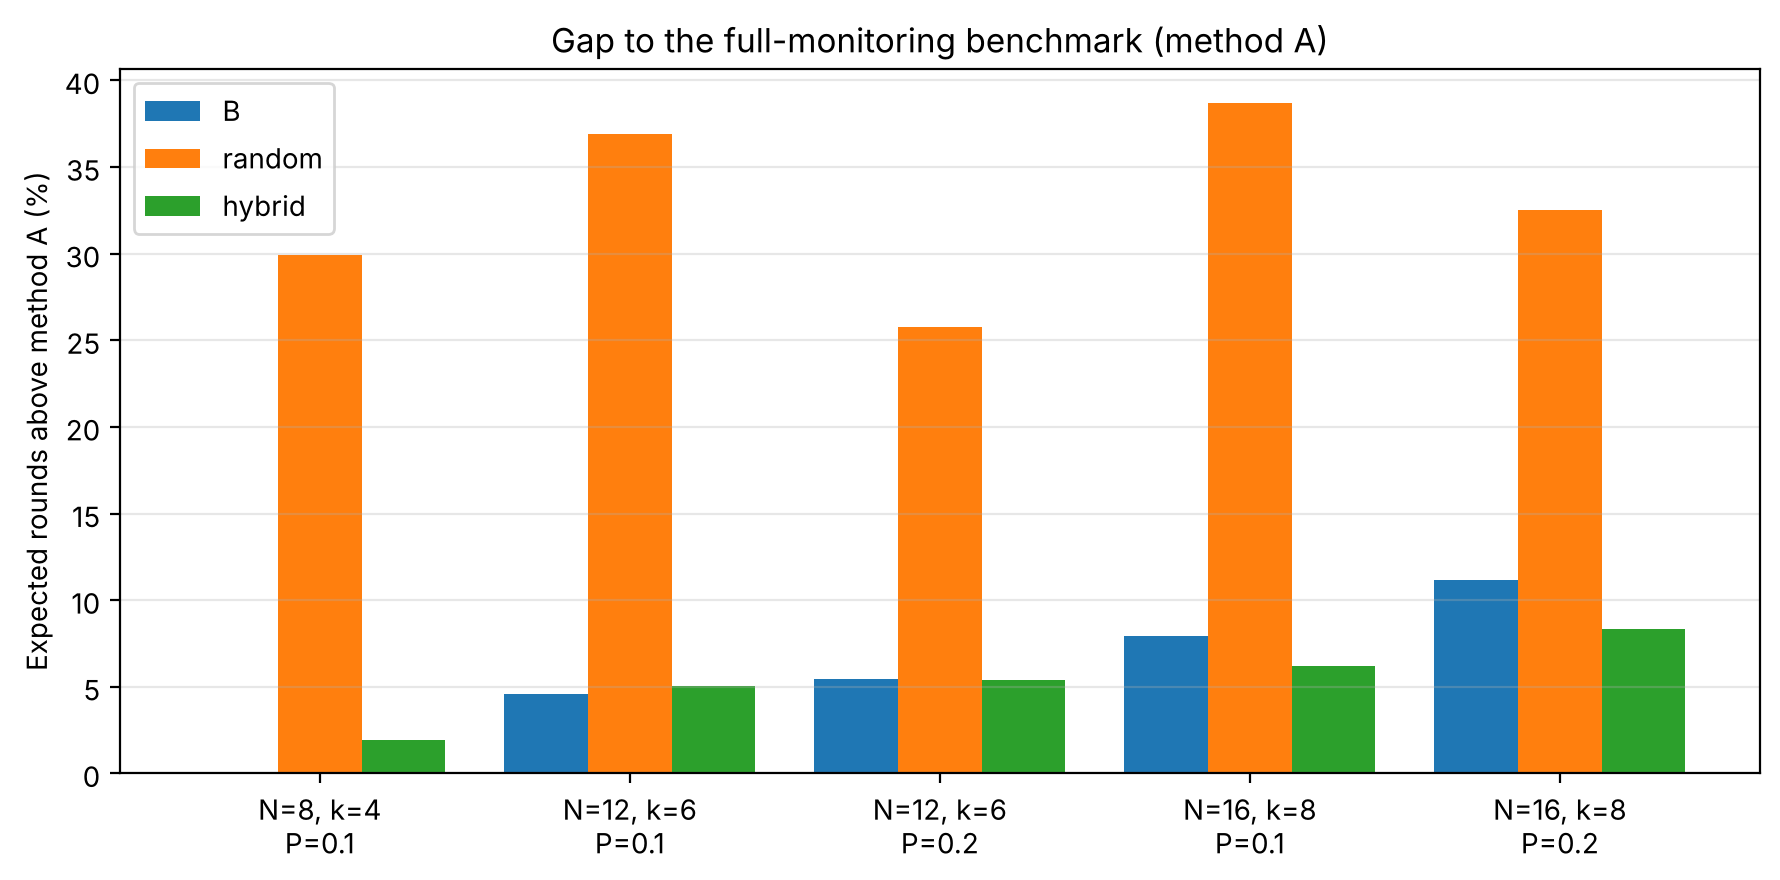

In [ ]:
# ---------- Chart: expected-time gap to method A ----------
labels = [f"N={N}, k={k}\nP={P}" for N, k, P in trial_cases]
width = 0.27
x = range(len(trial_cases))

plt.figure(figsize=(9, 4.5))
for i, d in enumerate(["B", "random", "hybrid"]):
    gaps = [100 * (results[c][d][0] / results[c]["A"][0] - 1) for c in trial_cases]
    plt.bar([xi + (i - 1) * width for xi in x], gaps, width, label=d)
plt.xticks(list(x), labels)
plt.ylabel("Expected rounds above method A (%)")
plt.title("Gap to the full-monitoring benchmark (method A)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("images/g_schedule_gap.png", dpi=150)
plt.show()